In [1]:
# Import Path to manage file locations
from pathlib import Path

# Import pandas to load and analyze evaluation results
import pandas as pd

# Import matplotlib for plotting model performance
import matplotlib.pyplot as plt

# Import seaborn for improved visualizations
import seaborn as sns

# Apply a consistent chart style
sns.set_theme(style="whitegrid")

In [3]:
# Define the location of the saved model metrics
METRICS_PATH = Path("../data/processed/model_metrics.csv")

# Load the metrics table
metrics_df = pd.read_csv(METRICS_PATH)

# Display the complete comparison table
display(metrics_df.round(4))

,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.965,0.9987,0.9650,0.965,0.9650,0.9534
1,Decision Tree,0.830,0.8867,0.8319,0.830,0.8302,0.7738
2,KNN,0.500,0.7697,0.5211,0.500,0.5054,0.3350
3,Naive Bayes,0.810,0.9506,0.8113,0.810,0.8105,0.7468
4,Support Vector Machine,0.895,0.9834,0.8969,0.895,0.8956,0.8602


In [5]:
# Define the evaluation metrics required by the assignment
metric_columns = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

# Create a dictionary to store the best model for every metric
best_models_by_metric = {}

# Find the best model for each evaluation metric
for metric in metric_columns:
    # Locate the row with the highest value for the current metric
    best_row = metrics_df.loc[metrics_df[metric].idxmax()]

    # Store the model name and metric value
    best_models_by_metric[metric] = {
        "Model": best_row["ML Model Name"],
        "Score": best_row[metric]
    }

# Convert the dictionary into a readable table
best_models_df = pd.DataFrame(best_models_by_metric).T

# Display the best-performing model for each metric
display(best_models_df.round(4))

,Model,Score
Accuracy,Logistic Regression,0.965
AUC,Logistic Regression,0.998667
Precision,Logistic Regression,0.965045
Recall,Logistic Regression,0.965
F1 Score,Logistic Regression,0.964986
MCC,Logistic Regression,0.953357


In [7]:
# Sort models primarily by weighted F1 Score
# Use MCC and AUC as tie-breaking criteria
ranked_models = metrics_df.sort_values(
    by=["F1 Score", "MCC", "AUC"],
    ascending=False
).reset_index(drop=True)

# Add a ranking column
ranked_models.insert(
    0,
    "Rank",
    range(1, len(ranked_models) + 1)
)

# Display the ranked models
display(ranked_models.round(4))

,Rank,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,1,Logistic Regression,0.965,0.9987,0.9650,0.965,0.9650,0.9534
1,2,Support Vector Machine,0.895,0.9834,0.8969,0.895,0.8956,0.8602
2,3,Decision Tree,0.830,0.8867,0.8319,0.830,0.8302,0.7738
3,4,Naive Bayes,0.810,0.9506,0.8113,0.810,0.8105,0.7468
4,5,KNN,0.500,0.7697,0.5211,0.500,0.5054,0.3350


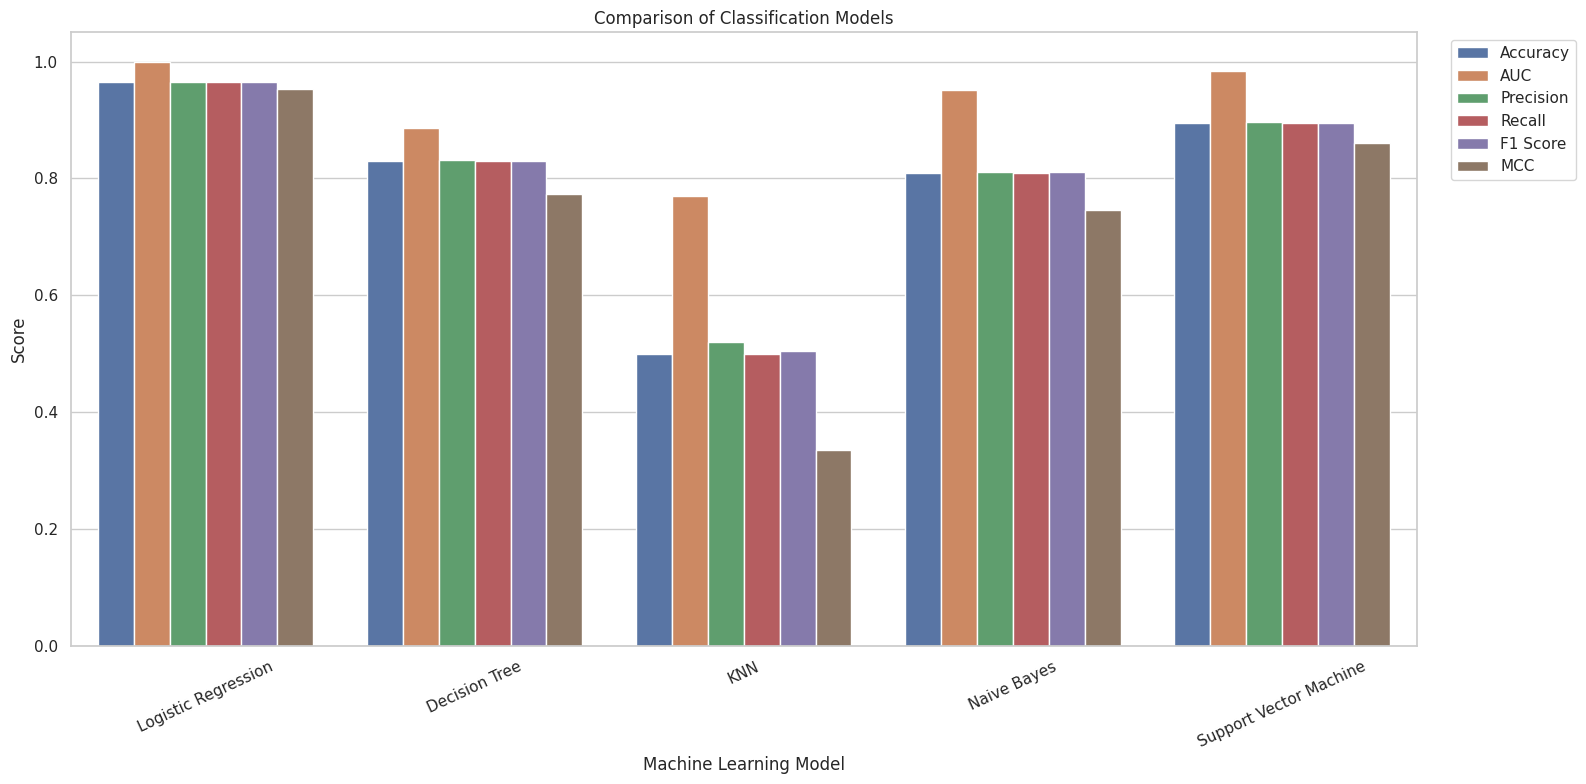

In [9]:
# Convert the metrics table into a long format for plotting
metrics_long = metrics_df.melt(
    id_vars="ML Model Name",
    value_vars=metric_columns,
    var_name="Metric",
    value_name="Score"
)

# Create a grouped bar chart
plt.figure(figsize=(16, 8))

# Plot each metric for every model
sns.barplot(
    data=metrics_long,
    x="ML Model Name",
    y="Score",
    hue="Metric"
)

# Add a descriptive title
plt.title("Comparison of Classification Models")

# Label the horizontal axis
plt.xlabel("Machine Learning Model")

# Label the vertical axis
plt.ylabel("Score")

# Rotate model names for readability
plt.xticks(rotation=25)

# Keep the score range consistent
plt.ylim(0, 1.05)

# Display the legend outside the main plot area
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

# Adjust the chart layout
plt.tight_layout()

# Display the plot
plt.show()

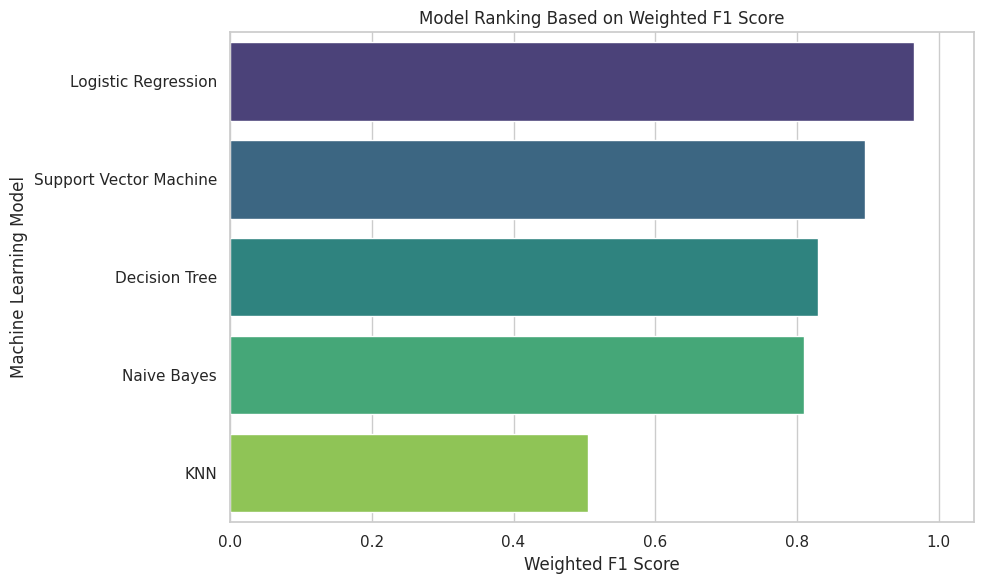

In [11]:
# Create a bar chart showing the F1 Score of every model
plt.figure(figsize=(10, 6))

# Plot models in ranked order
sns.barplot(
    data=ranked_models,
    x="F1 Score",
    y="ML Model Name",
    hue="ML Model Name",
    palette="viridis",
    legend=False
)

# Add a descriptive title
plt.title("Model Ranking Based on Weighted F1 Score")

# Label the horizontal axis
plt.xlabel("Weighted F1 Score")

# Label the vertical axis
plt.ylabel("Machine Learning Model")

# Set the score range
plt.xlim(0, 1.05)

# Display the plot
plt.tight_layout()

# Display the ranking chart
plt.show()

In [13]:
# Select the highest-ranked model
winner = ranked_models.iloc[0]

# Display the overall winner
print("Overall winner:", winner["ML Model Name"])

# Display the winner's complete metric values
display(winner.to_frame().T.round(4))

Overall winner: Logistic Regression


,Rank,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,1,Logistic Regression,0.965,0.998667,0.965045,0.965,0.964986,0.953357


In [15]:
# Define the output folder
PROCESSED_DIR = Path("../data/processed")

# Save the ranked comparison table
ranked_models.to_csv(
    PROCESSED_DIR / "model_comparison.csv",
    index=False
)

# Save the best model for each metric
best_models_df.to_csv(
    PROCESSED_DIR / "best_model_by_metric.csv"
)

# Confirm that the files were saved
print("Comparison files saved successfully.")

Comparison files saved successfully.
